In [35]:
import numpy as np
import pandas as pd
import seaborn as sns
import seaborn.objects as so
from formulaic import model_matrix
from sklearn import linear_model
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import PolynomialFeatures

In [ ]:
pip install formulaic

In [15]:
penguins = sns.load_dataset("penguins")
penguins.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [16]:
penguins.isnull().values.any()

True

In [17]:
penguins = penguins.dropna()
penguins.reindex()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,Male
...,...,...,...,...,...,...,...
338,Gentoo,Biscoe,47.2,13.7,214.0,4925.0,Female
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,Female
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,Male
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,Female


In [18]:
train_ind = np.full(333,False)
train_ind[0:265] = True
np.random.shuffle(train_ind)
p_train = penguins[train_ind == True]
p_test = penguins[train_ind == False]

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
p_sk_train, p_sk_test = train_test_split(penguins, test_size = 20, random_state = 42)

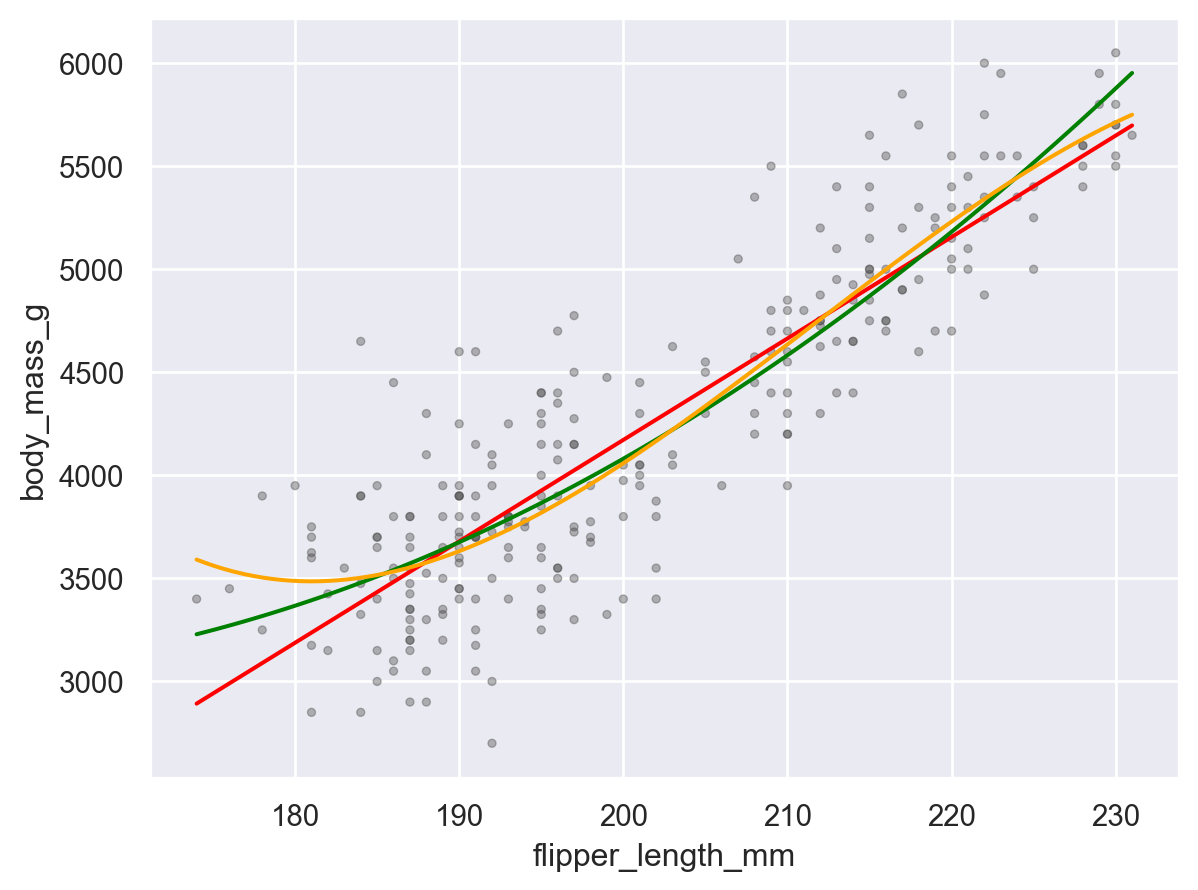

In [21]:
(
    so.Plot(data = p_train, x = "flipper_length_mm", y = "body_mass_g")
    .add(so.Dot(color = "0.3", alpha = 0.4, pointsize=3))
    .add(so.Line(color="red"), so.PolyFit(1))
    .add(so.Line(color="green"), so.PolyFit(2))
    .add(so.Line(color="orange"), so.PolyFit(3))
)

In [25]:
def poli(grado, data, test, x, y):
  polynomial_features= PolynomialFeatures(degree= grado, include_bias=False)

  x_poly = polynomial_features.fit_transform(data[[x]])
  x_poly_test = polynomial_features.fit_transform(test[[x]])

  modelo = linear_model.LinearRegression()

  modelo.fit(x_poly, data[y])

  beta = modelo.coef_

  o_origen = modelo.intercept_.item()

  y_pred = modelo.predict(x_poly_test)

  r2 = r2_score(test[y], y_pred)

  ecm = mean_squared_error(test[y], y_pred)


  return (o_origen, beta, r2, ecm)

def best_poli(grado, data, test, x, y):

  mejor_poli = 1
  for i in range (2, grado):
    if (poli(i, data, test, x, y)[2] < poli(mejor_poli, data, test, x, y)[2]):
      mejor_poli = i


  return mejor_poli

In [31]:
best_poli(3, p_train, p_test, "flipper_length_mm", "body_mass_g")

1

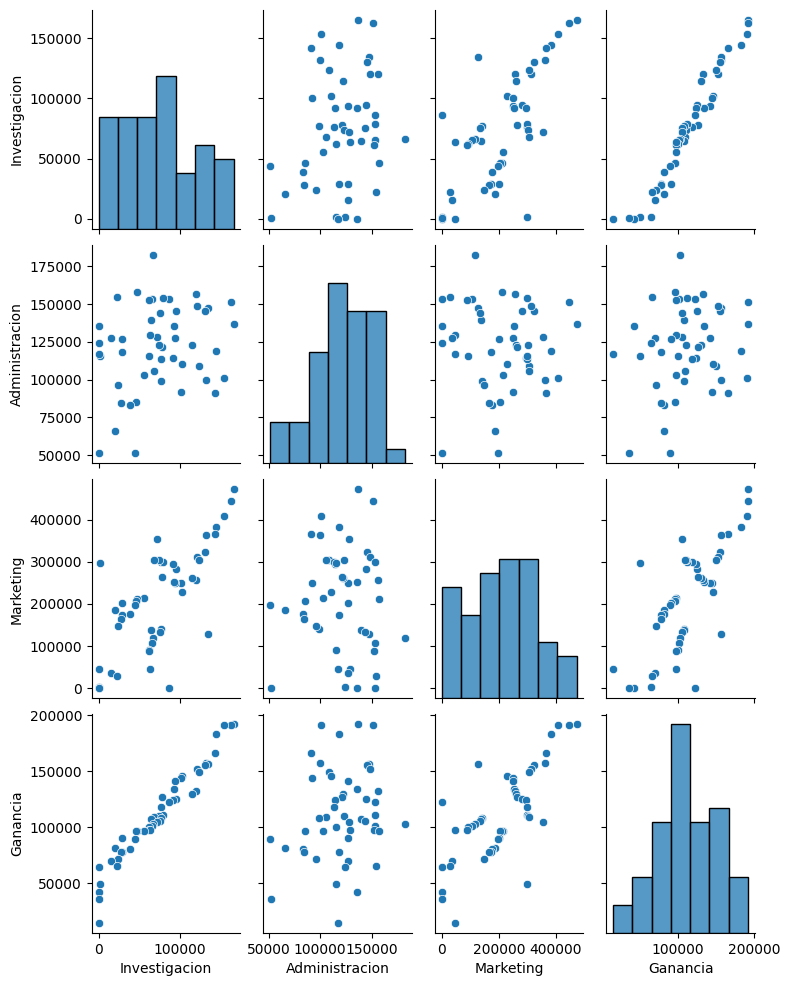

In [32]:
startups = pd.read_csv("/Users/fela/Desktop/Facu/codigofela/ldd/Datasets/50_Startups.csv")
sns.pairplot(
    data=startups, aspect = .8
)

In [33]:
startups.head()

,Investigacion,Administracion,Marketing,Estado,Ganancia
0,165349.20,136897.80,471784.10,New York,192261.83
1,162597.70,151377.59,443898.53,California,191792.06
2,153441.51,101145.55,407934.54,Florida,191050.39
3,144372.41,118671.85,383199.62,New York,182901.99
4,142107.34,91391.77,366168.42,Florida,166187.94


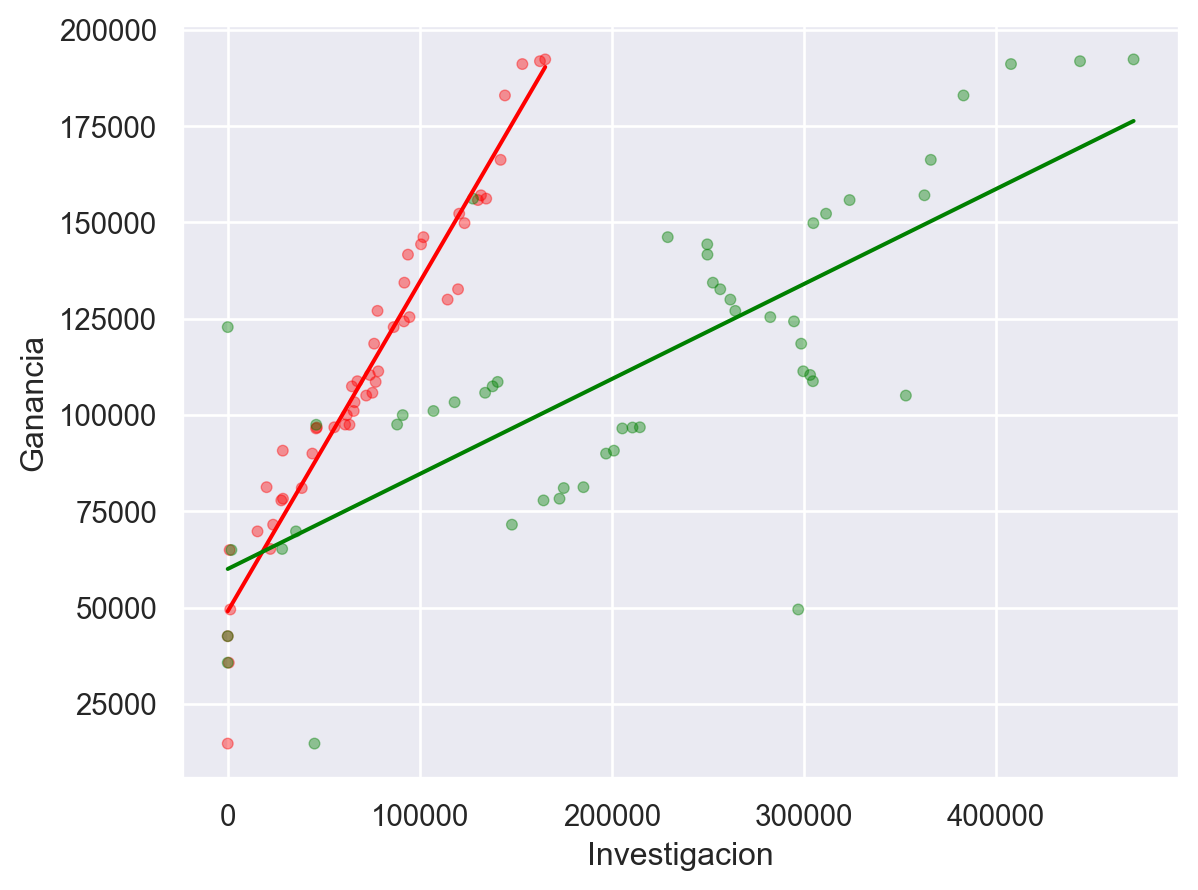

In [83]:
(
    so.Plot(data = startups, y = "Ganancia")
    .add(so.Dot(color = "red", alpha = 0.4, pointsize=4),x = "Investigacion")
    .add(so.Dot(color = "green", alpha = 0.4, pointsize=4),x = "Marketing")
    .add(so.Line(color="red"), so.PolyFit(1), x = "Investigacion")
    .add(so.Line(color="green"), so.PolyFit(1), x = "Marketing")
)

In [80]:
Ganancia, X = model_matrix('Ganancia ~ Investigacion : Marketing', startups)
valores_su = pd.concat([Ganancia, X], axis=1)
valores_su.head()

,Ganancia,Intercept,Investigacion:Marketing
0,192261.83,1.0,7.800912e+10
1,191792.06,1.0,7.217688e+10
2,191050.39,1.0,6.259409e+10
3,182901.99,1.0,5.532345e+10
4,166187.94,1.0,5.203522e+10


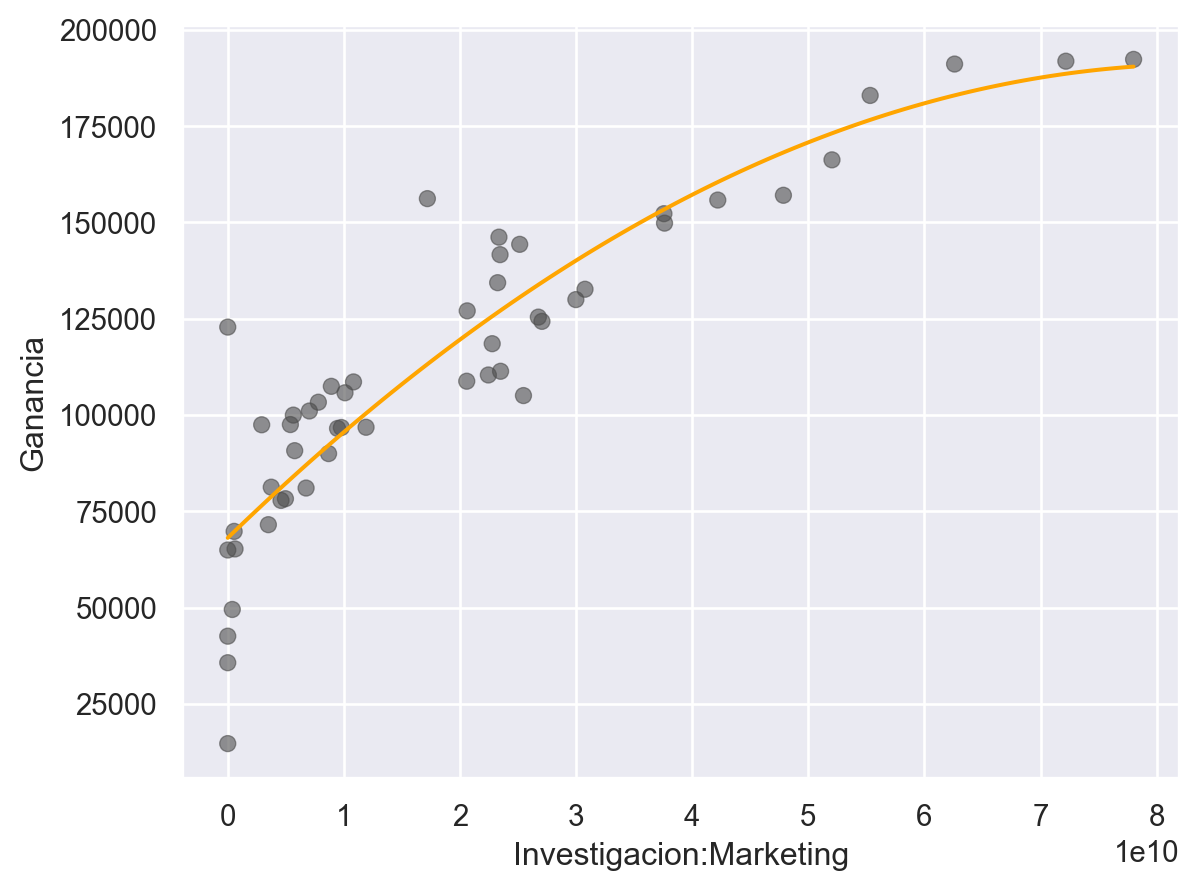

In [72]:
(
    so.Plot(
        data = valores_su,
        y = 'Ganancia',
        x = 'Investigacion:Marketing',
    )
    .add(so.Dot(color = ".3", alpha = '.6'))
    .add(so.Line(color = "orange"), so.PolyFit(2))
)

In [78]:
p_train.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,sex01
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male,1.0
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female,0.0
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female,0.0
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,Male,1.0
6,Adelie,Torgersen,38.9,17.8,181.0,3625.0,Female,0.0


In [77]:
from sklearn.preprocessing import OrdinalEncoder 
encoder = OrdinalEncoder()
sex01 = encoder.fit_transform(p_train[["sex"]]) 
p_train["sex01"] = sex01

/var/folders/wf/gvvhg49s5cngtjfy97vkmrqc0000gn/T/ipykernel_3019/1907548798.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  p_train["sex01"] = sex01


In [82]:
body_mass_g, X = model_matrix('body_mass_g ~ flipper_length_mm : sex01', p_train)
valores_p = pd.concat([body_mass_g, X], axis=1)
valores_p.head()

,body_mass_g,Intercept,flipper_length_mm:sex01
0,3750.0,1.0,181.0
1,3800.0,1.0,0.0
2,3250.0,1.0,0.0
5,3650.0,1.0,190.0
6,3625.0,1.0,0.0


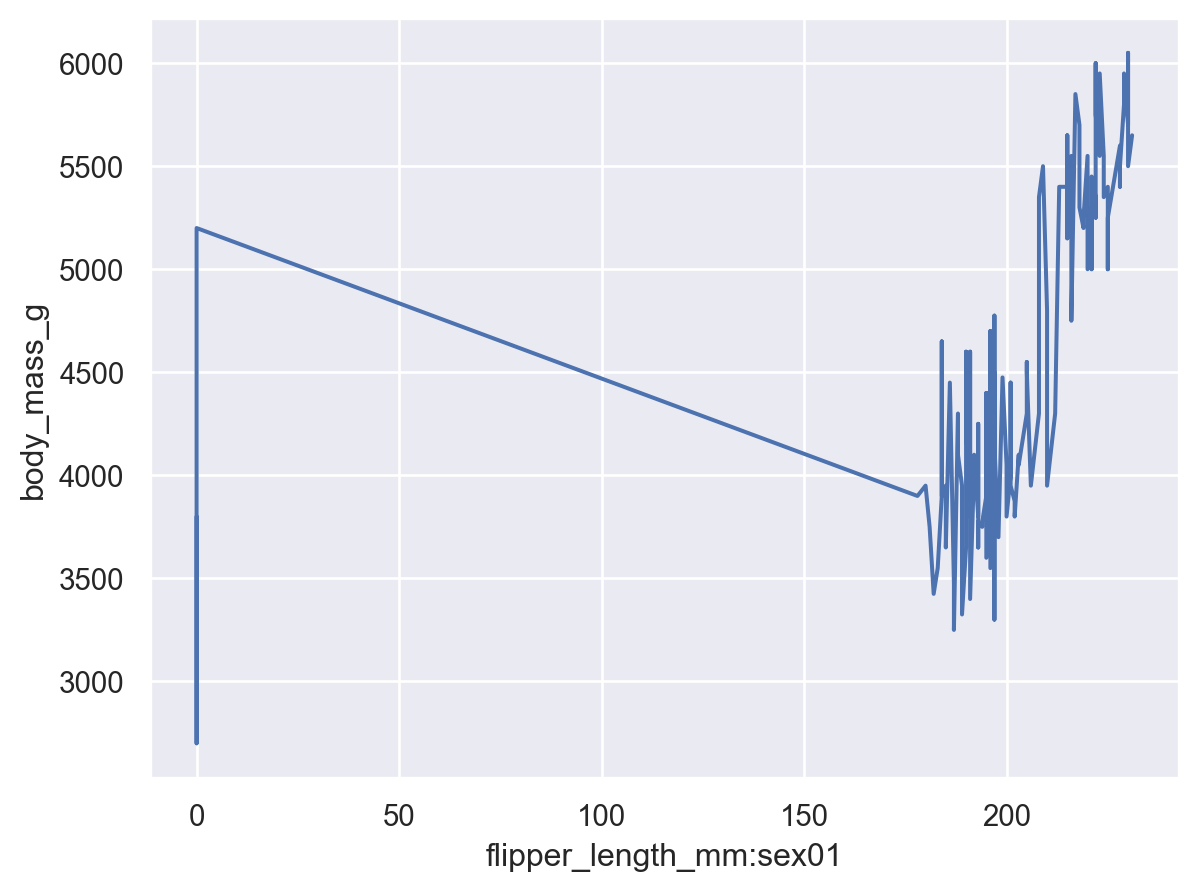

In [85]:
(
    so.Plot(
        data = valores_p,
        y = 'body_mass_g',
        x = 'flipper_length_mm:sex01'
    )
    .add(so.Line())
)

In [87]:
from sklearn.preprocessing import OneHotEncoder
encoderOHE = OneHotEncoder(sparse_output = False)
species3 = encoderOHE.fit_transform(penguins[["species"]]) 
species3_df = pd.DataFrame(species3 ,
columns=encoderOHE.get_feature_names_out(), index=penguins.index)
penguins3 = pd.concat([penguins, species3_df], axis = 1) 
penguins3.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,species_Adelie,species_Chinstrap,species_Gentoo
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male,1.0,0.0,0.0
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female,1.0,0.0,0.0
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female,1.0,0.0,0.0
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female,1.0,0.0,0.0
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,Male,1.0,0.0,0.0


In [88]:
body_mass_g3, X= model_matrix('body_mass_g ~ flipper_length_mm : (species_Adelie + species_Chinstrap + species_Gentoo)', penguins3)
valores_p3 = pd.concat([body_mass_g3, X], axis=1)
valores_p3.head()

,body_mass_g,Intercept,flipper_length_mm:species_Adelie,flipper_length_mm:species_Chinstrap,flipper_length_mm:species_Gentoo
0,3750.0,1.0,181.0,0.0,0.0
1,3800.0,1.0,186.0,0.0,0.0
2,3250.0,1.0,195.0,0.0,0.0
4,3450.0,1.0,193.0,0.0,0.0
5,3650.0,1.0,190.0,0.0,0.0
